<a href="https://colab.research.google.com/github/ganapriyahs/learn_ml_with_me/blob/main/Logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic Regression = Classification
#### In this file I walk through my learning process of logistic regression, the supervised learning model I learnt right after linear regression.

Linear regression predicts a *number* (a price). Logistic regression predicts a *category* (yes / no). Even though the word "regression" is in the name, it is a **classification** algorithm.

In this notebook I do two things:
1. **Plain logistic regression** - decide whether a student gets admitted based on two exam scores.
2. **Regularized logistic regression** - decide whether a microchip passes quality control, where a straight line is not enough.

> The course lab uses two small CSV files. Here I generate similar data with NumPy so the notebook runs anywhere without uploading anything.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

## 1. Why not just use linear regression?
If I fit a straight line to 0/1 labels, the output can be -3 or 7 - not a probability. And a single far-away point can tilt the line and flip predictions for everyone else.

I need a function that squeezes any number into the range **0 to 1**. That is the **sigmoid**:

$$g(z) = \frac{1}{1+e^{-z}}$$

The model is: $f_{w,b}(x) = g(w \cdot x + b)$, and I read the output as *P(y = 1 | x)*.

sigmoid(0)   = 0.5
sigmoid(10)  = 0.9999546021312976
sigmoid(-10) = 4.5397868702434395e-05


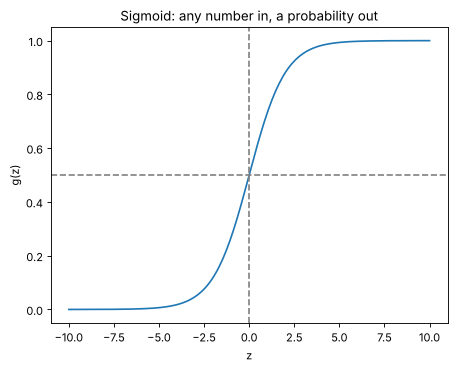

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-10, 10, 200)
plt.plot(z, sigmoid(z))
plt.axhline(0.5, ls='--', c='grey'); plt.axvline(0, ls='--', c='grey')
plt.title("Sigmoid: any number in, a probability out"); plt.xlabel("z"); plt.ylabel("g(z)")
plt.show()
print("sigmoid(0)   =", sigmoid(0))
print("sigmoid(10)  =", sigmoid(10))
print("sigmoid(-10) =", sigmoid(-10))

- `z = 0` gives exactly 0.5 - that is the **decision boundary** (predict 1 when $w\cdot x+b \ge 0$).
- Large positive z -> close to 1, large negative z -> close to 0.

## 2. The dataset: exam scores -> admitted?

In [3]:
rng = np.random.default_rng(1)
n = 100
X_rej = rng.normal([50, 50], 12, size=(n//2, 2))      # not admitted
X_acc = rng.normal([70, 68], 12, size=(n//2, 2))      # admitted
X_train = np.vstack([X_rej, X_acc])
y_train = np.hstack([np.zeros(n//2), np.ones(n//2)])
print("X_train shape:", X_train.shape, "| y_train shape:", y_train.shape)
print("First 5 rows:\n", X_train[:5].round(1), y_train[:5])

X_train shape: (100, 2) | y_train shape: (100,)
First 5 rows:
 [[54.1 59.9]
 [54.  34.4]
 [60.9 55.4]
 [43.6 57. ]
 [54.4 53.5]] [0. 0. 0. 0. 0.]


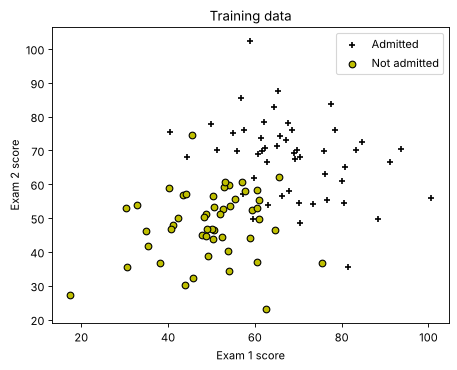

In [4]:
def plot_data(X, y, pos_label="Admitted", neg_label="Not admitted"):
    plt.scatter(X[y==1, 0], X[y==1, 1], marker='+', c='k', label=pos_label)
    plt.scatter(X[y==0, 0], X[y==0, 1], marker='o', c='y', edgecolors='k', label=neg_label)

plot_data(X_train, y_train)
plt.xlabel("Exam 1 score"); plt.ylabel("Exam 2 score"); plt.legend(); plt.title("Training data")
plt.show()

## 3. Cost function
For linear regression I used squared error. With a sigmoid inside, squared error makes the cost surface bumpy (not convex), so gradient descent can get stuck. Logistic regression uses the **log loss** instead:

$$loss(f, y) = -y\log(f) - (1-y)\log(1-f)$$

Intuition: if the true label is 1 and I predict 0.99, loss is tiny. If I predict 0.01 the loss is huge, because $-\log(0.01)$ is big. Confident and wrong is punished hardest.

$$J(w,b) = \frac{1}{m}\sum_{i=1}^{m} loss\big(f_{w,b}(x^{(i)}), y^{(i)}\big)$$

In [5]:
def compute_cost(X, y, w, b):
    m = X.shape[0]
    f = sigmoid(X @ w + b)
    return -np.mean(y * np.log(f) + (1 - y) * np.log(1 - f))

# sanity check: with w = 0, b = 0 every prediction is 0.5, so cost must be -log(0.5)
print("cost at w=0,b=0:", compute_cost(X_train, y_train, np.zeros(2), 0.0))
print("-log(0.5)      :", -math.log(0.5))

cost at w=0,b=0: 0.6931471805599453
-log(0.5)      : 0.6931471805599453


## 4. Gradient
Surprise: the gradient has *exactly the same form* as linear regression. Only $f$ is different (it has the sigmoid inside).

$$\frac{\partial J}{\partial w_j} = \frac{1}{m}\sum_i (f^{(i)} - y^{(i)})\,x_j^{(i)} \qquad \frac{\partial J}{\partial b} = \frac{1}{m}\sum_i (f^{(i)} - y^{(i)})$$

In [6]:
def compute_gradient(X, y, w, b):
    m = X.shape[0]
    err = sigmoid(X @ w + b) - y
    return X.T @ err / m, np.mean(err)

# check my analytic gradient against a numerical one - a habit I want to keep
w0, b0 = np.array([0.01, -0.02]), 0.5
dw, db = compute_gradient(X_train, y_train, w0, b0)
eps = 1e-6
num_dw = [(compute_cost(X_train, y_train, w0 + eps*np.eye(2)[j], b0) -
           compute_cost(X_train, y_train, w0 - eps*np.eye(2)[j], b0)) / (2*eps) for j in range(2)]
print("analytic :", dw, db)
print("numerical:", np.array(num_dw))

analytic : [-5.52935808 -6.70378224] -0.017441932453567253
numerical: [-5.52935808 -6.70378223]


## 5. Gradient descent
Same loop as before: compute gradient, step downhill, repeat. 

One thing I learnt the hard way: the two exam scores are in the range 20-100. Features that big make gradient descent crawl or blow up, so I **standardize** them first (subtract mean, divide by std).

In [7]:
def gradient_descent(X, y, w, b, alpha, num_iters):
    J_history = []
    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        J_history.append(compute_cost(X, y, w, b))
        if i % math.ceil(num_iters / 10) == 0:
            print(f"Iteration {i:5}: cost {J_history[-1]:.4f}")
    return w, b, J_history

mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
X_norm = (X_train - mu) / sigma

w, b, J_hist = gradient_descent(X_norm, y_train, np.zeros(2), 0.0, alpha=0.1, num_iters=1000)
print("w, b =", w, b)

Iteration     0: cost 0.6723
Iteration   100: cost 0.2732
Iteration   200: cost 0.2311
Iteration   300: cost 0.2145
Iteration   400: cost 0.2055
Iteration   500: cost 0.2000
Iteration   600: cost 0.1963
Iteration   700: cost 0.1937
Iteration   800: cost 0.1918
Iteration   900: cost 0.1903
w, b = [2.95314767 2.89541739] -0.051444849636608045


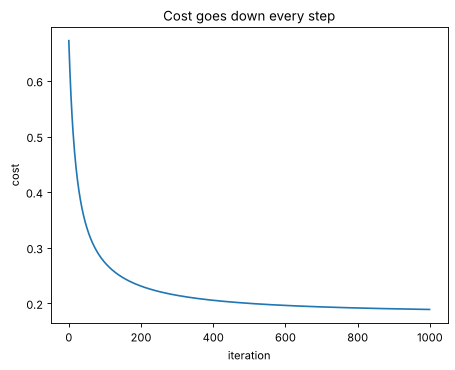

In [8]:
plt.plot(J_hist); plt.xlabel("iteration"); plt.ylabel("cost"); plt.title("Cost goes down every step")
plt.show()

## 6. Decision boundary
The boundary is where $w\cdot x + b = 0$. With two features it is a straight line.

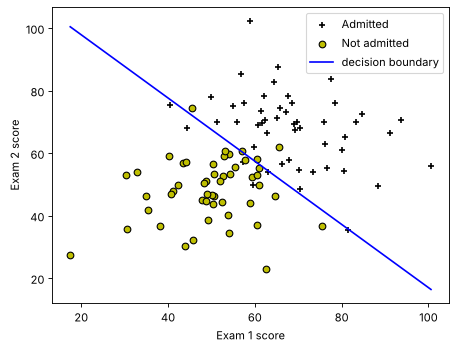

In [9]:
def plot_boundary_linear(X, y, w, b, mu, sigma):
    plot_data(X, y)
    x1 = np.array([X[:, 0].min(), X[:, 0].max()])
    xn = (x1 - mu[0]) / sigma[0]
    x2n = -(w[0] * xn + b) / w[1]               # boundary in normalized space
    x2 = x2n * sigma[1] + mu[1]                 # back to original units
    plt.plot(x1, x2, c='b', label="decision boundary")
    plt.xlabel("Exam 1 score"); plt.ylabel("Exam 2 score"); plt.legend()

plot_boundary_linear(X_train, y_train, w, b, mu, sigma)
plt.show()

## 7. Evaluating: predict() and accuracy
`predict` just thresholds the probability at 0.5.

In [10]:
def predict(X, w, b):
    return (sigmoid(X @ w + b) >= 0.5).astype(int)

p = predict(X_norm, w, b)
print("Train accuracy: %.1f%%" % (np.mean(p == y_train) * 100))

# a new student: 60 on exam 1, 70 on exam 2
new = (np.array([[60, 70]]) - mu) / sigma
print("P(admitted) for (60, 70):", sigmoid(new @ w + b).round(3))

Train accuracy: 90.0%
P(admitted) for (60, 70): [0.924]


---
# Part 2 - Regularized logistic regression
Now the microchip problem: two test results per chip, label = pass / fail. The classes sit in a **circle**, so no straight line can separate them.

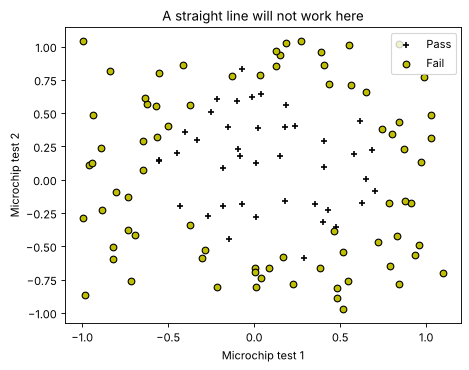

In [11]:
rng = np.random.default_rng(3)
Xc = rng.uniform(-1, 1.1, size=(118, 2))
r = np.sqrt((Xc[:, 0] - 0.1) ** 2 + (Xc[:, 1] - 0.1) ** 2) + rng.normal(0, 0.08, 118)
yc = (r < 0.65).astype(float)
plot_data(Xc, yc, "Pass", "Fail")
plt.xlabel("Microchip test 1"); plt.ylabel("Microchip test 2"); plt.legend(); plt.title("A straight line will not work here")
plt.show()

## Feature mapping
Trick: create new features from the old ones (all polynomial terms up to degree 6). A *linear* model on those features draws a *curved* boundary on the original axes. 2 features -> 27 features.

In [12]:
def map_feature(X1, X2, degree=6):
    cols = []
    for i in range(1, degree + 1):
        for j in range(i + 1):
            cols.append((X1 ** (i - j)) * (X2 ** j))
    return np.stack(cols, axis=1)

X_mapped = map_feature(Xc[:, 0], Xc[:, 1])
print("original:", Xc.shape, "-> mapped:", X_mapped.shape)

original: (118, 2) -> mapped: (118, 27)


## Regularization
With 27 features the model can twist itself to hit every training point (overfitting). Regularization adds a penalty for big weights:

$$J_{reg}(w,b) = J(w,b) + \frac{\lambda}{2m}\sum_j w_j^2$$

and the gradient gets one extra term for each weight: $\frac{\lambda}{m} w_j$. (The bias $b$ is **not** regularized.) 
Large $\lambda$ -> simpler, smoother model (can underfit). $\lambda = 0$ -> no protection.

In [13]:
def compute_cost_reg(X, y, w, b, lambda_=1):
    return compute_cost(X, y, w, b) + (lambda_ / (2 * X.shape[0])) * np.sum(w ** 2)

def compute_gradient_reg(X, y, w, b, lambda_=1):
    dj_dw, dj_db = compute_gradient(X, y, w, b)
    return dj_dw + (lambda_ / X.shape[0]) * w, dj_db

def gradient_descent_reg(X, y, w, b, alpha, num_iters, lambda_):
    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient_reg(X, y, w, b, lambda_)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
    return w, b

def plot_boundary_mapped(X, y, w, b, ax_title):
    plot_data(X, y, "Pass", "Fail")
    u = np.linspace(X[:, 0].min() - .1, X[:, 0].max() + .1, 100)
    v = np.linspace(X[:, 1].min() - .1, X[:, 1].max() + .1, 100)
    z = np.array([[map_feature(np.array([ui]), np.array([vj])) @ w + b for ui in u] for vj in v]).reshape(100, 100)
    plt.contour(u, v, z, levels=[0], colors='b')
    plt.title(ax_title); plt.xlabel("test 1"); plt.ylabel("test 2")

Let me compare three values of $\lambda$ on the same data to *see* underfitting vs overfitting.

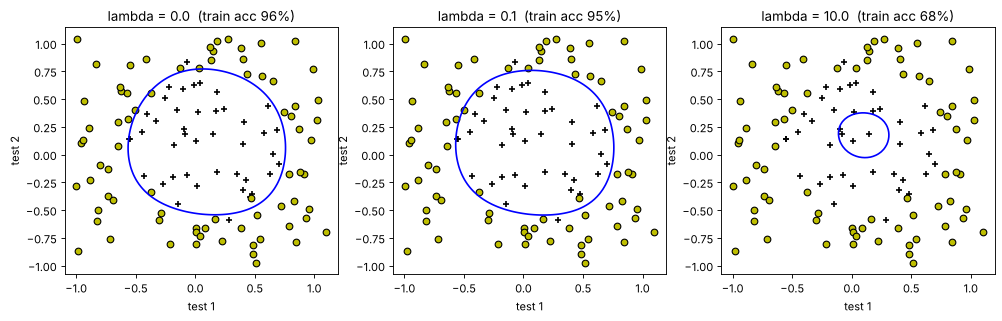

In [14]:
fig = plt.figure(figsize=(15, 4))
for k, lam in enumerate([0.0, 0.1, 10.0]):
    plt.subplot(1, 3, k + 1)
    w_r, b_r = gradient_descent_reg(X_mapped, yc, np.zeros(X_mapped.shape[1]), 0.0, alpha=0.5, num_iters=8000, lambda_=lam)
    acc = np.mean(predict(X_mapped, w_r, b_r) == yc) * 100
    plot_boundary_mapped(Xc, yc, w_r, b_r, f"lambda = {lam}  (train acc {acc:.0f}%)")
plt.show()

- $\lambda = 0$: wiggly boundary that chases individual points (overfit).
- $\lambda = 0.1$: smooth boundary close to the true circle.
- $\lambda = 10$: too much penalty, boundary gets vague and bends less (underfit).

## The scikit-learn version
Everything above is one line in scikit-learn. Note: sklearn's `C` is the **inverse** of regularization strength ($C \approx 1/\lambda$).

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# exam data
Xtr, Xte, ytr, yte = train_test_split(X_train, y_train, test_size=0.25, random_state=0, stratify=y_train)
sc = StandardScaler().fit(Xtr)
clf = LogisticRegression().fit(sc.transform(Xtr), ytr)
pred = clf.predict(sc.transform(Xte))
print("coef:", clf.coef_, "intercept:", clf.intercept_)
print("test accuracy:", accuracy_score(yte, pred))
print(confusion_matrix(yte, pred))
print(classification_report(yte, pred))

coef: [[1.87995321 1.99708813]] intercept: [-0.00150742]
test accuracy: 0.92
[[12  1]
 [ 1 11]]
              precision    recall  f1-score   support

         0.0       0.92      0.92      0.92        13
         1.0       0.92      0.92      0.92        12

    accuracy                           0.92        25
   macro avg       0.92      0.92      0.92        25
weighted avg       0.92      0.92      0.92        25



In [16]:
# microchip data with polynomial features + L2 regularization
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
for C in [1000, 10, 0.1]:
    model = make_pipeline(PolynomialFeatures(6), StandardScaler(), LogisticRegression(C=C, max_iter=5000))
    model.fit(Xc, yc)
    print(f"C = {C:>6}: train accuracy = {model.score(Xc, yc):.3f}")

C =   1000: train accuracy = 0.975
C =     10: train accuracy = 0.966
C =    0.1: train accuracy = 0.941


## Drawbacks / things to remember
- **Linear boundary by default.** I need feature mapping (or a different model) for curved boundaries, and that is manual work.
- **Too many features -> overfit.** That is exactly why regularization exists.
- **Feature scaling matters** for gradient descent (and for regularization to treat weights fairly).
- **Accuracy can lie** when classes are imbalanced (99% "not fraud" model is useless). Look at precision, recall and the confusion matrix.
- Output is a probability, but it is only well calibrated if the model is not badly over/underfit. The 0.5 threshold is a choice, not a law.